In [1]:
!pip install -q gensim

In [2]:
# Import required libraries
import numpy as np
import tensorflow as tf
import gensim
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Lambda
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
print("TensorFlow version:", tf.__version__)
print("Gensim version:", gensim.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Gensim version: 4.4.0
Libraries imported successfully!


In [3]:
# Create an English paragraph of 8 sentences
text = """
Machine learning is an important field of artificial intelligence.
Machine learning helps computers learn from data.
Deep learning uses neural networks to solve complex problems.
Neural networks learn useful patterns from large amounts of data.
Natural language processing helps computers understand human language.
Word embeddings represent words as numerical vectors.
The CBOW model predicts a target word using surrounding context words.
Word2Vec techniques are widely used for learning meaningful word representations.
"""
print(text)


Machine learning is an important field of artificial intelligence.
Machine learning helps computers learn from data.
Deep learning uses neural networks to solve complex problems.
Neural networks learn useful patterns from large amounts of data.
Natural language processing helps computers understand human language.
Word embeddings represent words as numerical vectors.
The CBOW model predicts a target word using surrounding context words.
Word2Vec techniques are widely used for learning meaningful word representations.



In [4]:
# Convert text to lowercase
text = text.lower()
# Remove punctuation
import string
text = text.translate(str.maketrans('', '', string.punctuation))
print(text)


machine learning is an important field of artificial intelligence
machine learning helps computers learn from data
deep learning uses neural networks to solve complex problems
neural networks learn useful patterns from large amounts of data
natural language processing helps computers understand human language
word embeddings represent words as numerical vectors
the cbow model predicts a target word using surrounding context words
word2vec techniques are widely used for learning meaningful word representations



In [6]:

# Split paragraph into individual sentences
sentences = [
    sentence.strip()
    for sentence in text.split('\n')
    if sentence.strip()
]
print("Total number of sentences:", len(sentences))
for i, sentence in enumerate(sentences, 1):
    print(i, ":", sentence)


Total number of sentences: 8
1 : machine learning is an important field of artificial intelligence
2 : machine learning helps computers learn from data
3 : deep learning uses neural networks to solve complex problems
4 : neural networks learn useful patterns from large amounts of data
5 : natural language processing helps computers understand human language
6 : word embeddings represent words as numerical vectors
7 : the cbow model predicts a target word using surrounding context words
8 : word2vec techniques are widely used for learning meaningful word representations


In [8]:
# Create tokenizer
tokenizer = Tokenizer()
# Fit tokenizer on the sentences
tokenizer.fit_on_texts(sentences)
# Convert sentences into sequences of word indices
sequences = tokenizer.texts_to_sequences(sentences)
print("Tokenized sentences:")
for sequence in sequences:
  print(sequence)

Tokenized sentences:
[3, 1, 14, 15, 16, 17, 4, 18, 19]
[3, 1, 5, 6, 7, 8, 9]
[20, 1, 21, 10, 11, 22, 23, 24, 25]
[10, 11, 7, 26, 27, 8, 28, 29, 4, 9]
[30, 12, 31, 5, 6, 32, 33, 12]
[2, 34, 35, 13, 36, 37, 38]
[39, 40, 41, 42, 43, 44, 2, 45, 46, 47, 13]
[48, 49, 50, 51, 52, 53, 1, 54, 2, 55]


In [9]:
# Find vocabulary size and number of sentences
word_index = tokenizer.word_index
total_vocab = len(word_index) + 1
total_sentences = len(sentences)
print("Total number of sentences:", total_sentences)
print("Total number of unique words:", len(word_index))
print("Total vocabulary size:", total_vocab)
print("\nWord Index:")
print(word_index)

Total number of sentences: 8
Total number of unique words: 55
Total vocabulary size: 56

Word Index:
{'learning': 1, 'word': 2, 'machine': 3, 'of': 4, 'helps': 5, 'computers': 6, 'learn': 7, 'from': 8, 'data': 9, 'neural': 10, 'networks': 11, 'language': 12, 'words': 13, 'is': 14, 'an': 15, 'important': 16, 'field': 17, 'artificial': 18, 'intelligence': 19, 'deep': 20, 'uses': 21, 'to': 22, 'solve': 23, 'complex': 24, 'problems': 25, 'useful': 26, 'patterns': 27, 'large': 28, 'amounts': 29, 'natural': 30, 'processing': 31, 'understand': 32, 'human': 33, 'embeddings': 34, 'represent': 35, 'as': 36, 'numerical': 37, 'vectors': 38, 'the': 39, 'cbow': 40, 'model': 41, 'predicts': 42, 'a': 43, 'target': 44, 'using': 45, 'surrounding': 46, 'context': 47, 'word2vec': 48, 'techniques': 49, 'are': 50, 'widely': 51, 'used': 52, 'for': 53, 'meaningful': 54, 'representations': 55}


In [10]:
# Set CBOW window size
window_size = 2
print("Window size:", window_size)
print("Maximum context words:", window_size * 2)

Window size: 2
Maximum context words: 4


In [12]:
# Generate CBOW context-target pairs
def generate_cbow_data(data, window_size, total_vocab):
    context_data = []
    target_data = []

    for sentence in data:
        sentence_length = len(sentence)
        for idx, word in enumerate(sentence):
            context_words = []
            begin = idx - window_size
            end = idx + window_size + 1

            for i in range(begin, end):
                if 0 <= i < sentence_length and i != idx:
                    context_words.append(sentence[i])
            # Pad context words to fixed length
            context_words = pad_sequences(
                [context_words],
                maxlen=window_size * 2,
                padding='pre'
            )[0]
            context_data.append(context_words)
            target_data.append(word)
    # Convert target values to one-hot encoding
    target_data = keras.utils.to_categorical(
        target_data,
        num_classes=total_vocab
    )
    return np.array(context_data), np.array(target_data)


In [13]:
# Generate training data
X, y = generate_cbow_data(
sequences,
window_size,
total_vocab
)
print("Context data shape:", X.shape)
print("Target data shape:", y.shape)

Context data shape: (71, 4)
Target data shape: (71, 56)


In [14]:
# Display some context-target examples
reverse_word_index = {
    value: key for key, value in word_index.items()
}
print("Sample CBOW training pairs:\n")
for i in range(min(10, len(X))):
    context_words = [
        reverse_word_index.get(word_id, "<PAD>")
        for word_id in X[i]
        if word_id != 0
    ]
    target_word = reverse_word_index.get(
        np.argmax(y[i]),
        "UNKNOWN"
    )
    print("Context:", context_words)
    print("Target :", target_word)
    print()


Sample CBOW training pairs:

Context: ['learning', 'is']
Target : machine

Context: ['machine', 'is', 'an']
Target : learning

Context: ['machine', 'learning', 'an', 'important']
Target : is

Context: ['learning', 'is', 'important', 'field']
Target : an

Context: ['is', 'an', 'field', 'of']
Target : important

Context: ['an', 'important', 'of', 'artificial']
Target : field

Context: ['important', 'field', 'artificial', 'intelligence']
Target : of

Context: ['field', 'of', 'intelligence']
Target : artificial

Context: ['of', 'artificial']
Target : intelligence

Context: ['learning', 'helps']
Target : machine



In [15]:
# Create CBOW model
embedding_dim = 100
model = Sequential([
# Convert word IDs into embedding vectors
Embedding(
input_dim=total_vocab,
output_dim=embedding_dim
),
# Average the context word embeddings
Lambda(
lambda x: tf.reduce_mean(x, axis=1)
),
# Fully connected layer
Dense(128, activation='relu'),
# Output layer
Dense(total_vocab, activation='softmax')
])
print("CBOW model created successfully!")

CBOW model created successfully!


In [16]:
# Build the model
model.build(input_shape=(None, window_size * 2))
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 4, 100)         │         5,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 56)             │         7,224 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,752 (100.59 KB)

 Trainable params: 25,752 (100.59 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Compile CBOW model
model.compile(
loss='categorical_crossentropy',
optimizer='adam',
metrics=['accuracy']
)
print("CBOW model compiled successfully!")


CBOW model compiled successfully!


In [18]:
# Train the CBOW model
history = model.fit(
X,
y,
epochs=100,
batch_size=16,
verbose=1
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.0000e+00 - loss: 4.0284
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1408 - loss: 4.0115 
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2113 - loss: 3.9990 
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2535 - loss: 3.9856 
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2958 - loss: 3.9705 
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3239 - loss: 3.9542 
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3380 - loss: 3.9346 
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3662 - loss: 3.9116 
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3803 - loss: 3.8860 
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3803 - loss: 3.8541 
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3380 - loss: 3.8184 
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3239 - 

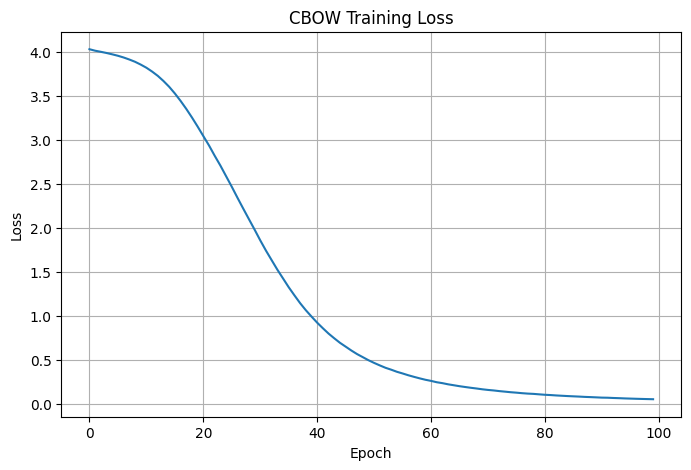

In [19]:
# Plot training loss
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'])
plt.title('CBOW Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()


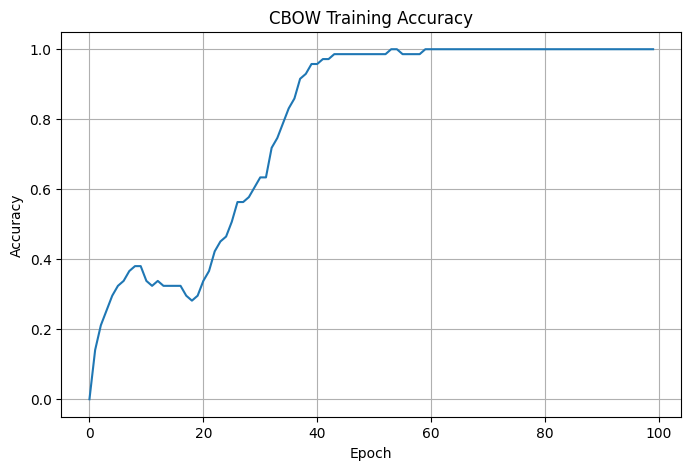

In [20]:
# Plot training accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'])
plt.title('CBOW Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.show()


In [21]:
# Extract word embedding weights
weights = model.get_weights()[0]
print("Embedding matrix shape:", weights.shape)
print("Embedding dimension:", embedding_dim)

Embedding matrix shape: (56, 100)
Embedding dimension: 100


In [24]:

# Create Word2Vec-compatible vector file
vector_file = "/content/vectors.txt"
with open(vector_file, "w") as f:
    # Header: vocabulary size and vector dimensions
    f.write(f"{total_vocab} {embedding_dim}\n")
    # Write embedding for index 0 (padding/unknown token)
    vector_for_zero = weights[0]
    vector_string_for_zero = " ".join(map(str, vector_for_zero))
    f.write(f"<PAD> {vector_string_for_zero}\n")
    for word, index in word_index.items():
        vector = weights[index]
        vector_string = " ".join(map(str, vector))
        f.write(f"{word} {vector_string}\n")

print("Vector file created successfully!")
print("File location:", vector_file)

Vector file created successfully!
File location: /content/vectors.txt


In [25]:
# Load the trained word vectors
from gensim.models import KeyedVectors
cbow_output = KeyedVectors.load_word2vec_format(
vector_file,
binary=False
)
print("Word vectors loaded successfully!")
print("Number of vectors:", len(cbow_output))
print("Vector size:", cbow_output.vector_size)

Word vectors loaded successfully!
Number of vectors: 56
Vector size: 100


In [27]:
# Find similar words
word = "learning"
similar_words = cbow_output.most_similar(
    positive=[word],
    topn=5
)
print(f"Words most similar to '{word}':")
for w, score in similar_words:
    print(f"{w}: {score:.4f}")


Words most similar to 'learning':
is: 0.4687
processing: 0.4104
representations: 0.3763
for: 0.3718
the: 0.3195


In [30]:
# Test another word
word = "model"
similar_words = cbow_output.most_similar(
    positive=[word],
    topn=5
)
print(f"Words most similar to '{word}':")
for w, score in similar_words:
    print(f"{w}: {score:.4f}")


Words most similar to 'model':
target: 0.6022
cbow: 0.5897
predicts: 0.5010
a: 0.3320
problems: 0.2960


In [31]:
# Display the vector of a word
word = "learning"
vector = cbow_output[word]
print("Word:", word)
print("Vector dimension:", len(vector))
print("\nFirst 10 values of vector:")
print(vector[:10])

Word: learning
Vector dimension: 100

First 10 values of vector:
[-0.13994946  0.06149606  0.15413491  0.02514206 -0.33114463  0.02931834
  0.1417619   0.2086112  -0.2705263   0.16950858]


In [34]:

# Display final CBOW results
print("=" * 50)
print("CBOW MODEL - FINAL RESULTS")
print("=" * 50)
print("Number of sentences :", total_sentences)
print("Vocabulary size      :", total_vocab)
print("Window size          :", window_size)
print("Embedding dimension  :", embedding_dim)
print("Training samples     :", len(X))
print("\nSelected word :", "learning")
print("\nSimilar words:")
for word, score in cbow_output.most_similar(
    positive=["learning"],
    topn=5
):
    print(f"{word:15s} : {score:.4f}")
print("=" * 50)


CBOW MODEL - FINAL RESULTS
Number of sentences : 8
Vocabulary size      : 56
Window size          : 2
Embedding dimension  : 100
Training samples     : 71

Selected word : learning

Similar words:
is              : 0.4687
processing      : 0.4104
representations : 0.3763
for             : 0.3718
the             : 0.3195
